# Experiment NO. 10
# Build a single layer ANN for a single classication problem

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

/home/anjali/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


# Step 1: Load the Iris dataset from CSV

In [22]:
df = pd.read_csv("/home/anjali/Downloads/iris.csv")

print("Original Dataset Shape:", df.shape)
print("\nFirst Five Rows:")
print(df.head())

Original Dataset Shape: (150, 5)

First Five Rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


# Step 2: Select input features and target

In [23]:
X = df[['sepal_length', 'sepal_width',
        'petal_length', 'petal_width']].values

# Convert species names into numerical labels
y = df['species'].astype(str).str.strip().str.lower().map({
    'setosa': 0,
    'versicolor': 1,
    'virginica': 2
}).values

# Check for invalid labels
if pd.isna(y).any():
    raise ValueError("Invalid species names found in the CSV file.")

# Select two classes: Setosa (0) and Versicolor (1)
mask = y < 2
X = X[mask]
y = y[mask]

# Step 3: Split dataset into training and testing sets

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 80
Testing Samples: 20


# Step 4: Standardize the input features

In [25]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Initialize weights and bias

In [26]:
np.random.seed(42)

weights = np.zeros(X_train.shape[1])
bias = 0.0

learning_rate = 0.1
epochs = 1000

# Step 6: Define the sigmoid activation function

In [27]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Step 7: Train the single-layer ANN

In [33]:
for epoch in range(epochs):

    # Calculate weighted sum
    z = np.dot(X_train, weights) + bias

    # Calculate output using sigmoid
    predictions = sigmoid(z)

    # Calculate prediction error
    error = predictions - y_train

    # Calculate gradients
    dw = np.dot(X_train.T, error) / len(y_train)
    db = np.mean(error)

    # Update weights and bias
    weights -= learning_rate * dw
    bias -= learning_rate * db

# Step 8: Predict test data

In [29]:
test_output = sigmoid(np.dot(X_test, weights) + bias)

y_pred = (test_output >= 0.5).astype(int)

# Step 9: Evaluate the model

In [30]:

accuracy = accuracy_score(y_test, y_pred)

print("\nActual Classes:   ", y_test)
print("Predicted Classes:", y_pred)

print(f"\nAccuracy: {accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Setosa', 'Versicolor'],
        zero_division=0
    )
)


Actual Classes:    [1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]
Predicted Classes: [1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]

Accuracy: 100.00%

Confusion Matrix:
[[10  0]
 [ 0 10]]

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



# Step 10: Predict a new flower

In [31]:
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

new_flower_scaled = scaler.transform(new_flower)

probability = sigmoid(
    np.dot(new_flower_scaled, weights) + bias
)[0]

predicted_class = int(probability >= 0.5)

class_names = ['Setosa', 'Versicolor']

print("\nNew Flower Prediction:")
print("Flower Measurements:", new_flower[0])
print("Predicted Species:", class_names[predicted_class])
print(f"Output Probability: {probability:.4f}")


New Flower Prediction:
Flower Measurements: [5.1 3.5 1.4 0.2]
Predicted Species: Setosa
Output Probability: 0.0021


# Step 11: Display the confusion matrix

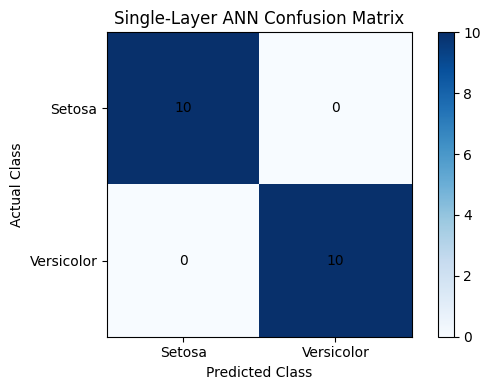

In [32]:
plt.figure(figsize=(6, 4))

plt.imshow(cm, cmap="Blues")
plt.title("Single-Layer ANN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ['Setosa', 'Versicolor'])
plt.yticks([0, 1], ['Setosa', 'Versicolor'])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()